T4 GPUが利用可能かどうか確認

In [ ]:
# 1. GPU (T4等) が利用可能か自動チェック
import sys
import torch

if torch.cuda.is_available():
    device = "cuda"
    gpu_name = torch.cuda.get_device_name(0)
    print(f"✅ GPUが有効です: {gpu_name}")
else:
    # CPUの場合は警告を出す
    print("⚠️ 警告: GPUが有効になっていません！")
    print("Colabの上部メニュー [ランタイム] -> [ランタイムのタイプを変更] から『T4 GPU』を選択してください。")

✅ GPUが有効です: Tesla T4


In [ ]:
from PIL import Image, ImageOps
from io import BytesIO
import requests
from matplotlib import pyplot as plt

PCから、画像データを読み込む

Saving meet_pic.png to meet_pic.png
画像のサイズ (幅, 高さ)ピクセル: (451, 357)


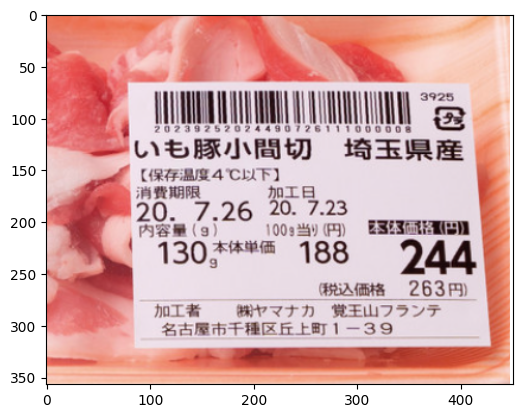

In [ ]:
# セル4：自分のPCから写真のアップロード
from google.colab import files
from PIL import Image, ImageOps
uploaded = files.upload()
image_path = next(iter(uploaded))
img_pil = Image.open(image_path)
img_pil = ImageOps.exif_transpose(img_pil)  # スマホ写真の向きを補正
img_pil = img_pil.convert("RGB")
#img_pil.thumbnail((1024, 1024))  # 大きな写真は縮小してメモリを節約
print(f"画像のサイズ (幅, 高さ)ピクセル: {img_pil.size}")
plt.imshow(img_pil) # 画像を描かせる
plt.show()

セル1：ライブラリのインストール

In [ ]:
# セル1：ライブラリのインストール
!pip install -q -U "transformers>=4.57.0" accelerate "click<8.2"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
spacy 3.8.18 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 1.16.1 which is incompatible.


In [ ]:
#セル2：モジュールのインポート(重要)
import torch
from transformers import Qwen3VLForConditionalGeneration, AutoProcessor

In [ ]:
# セル3：モデルのダウンロード・読み込み
MODEL_ID = "Qwen/Qwen3-VL-2B-Instruct"
# Hugging FaceからColabにダウンロード
model = Qwen3VLForConditionalGeneration.from_pretrained(
         MODEL_ID,
         dtype=torch.float16,
         device_map="cuda",
)
processor = AutoProcessor.from_pretrained(MODEL_ID)
model.eval()

print("モデルの読み込み完了")


config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/4.26G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

... (2 outputs left out)

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

モデルの読み込み完了


In [ ]:
# セル5：プロンプトを入力して実行

prompt = """
         商品ラベルの写真。値段が日本円で書いてあります。
         商品名と、価格(Yen)を書き出してください。
      　"""

messages = [
            {
                 "role": "user",
                 "content": [
                          {"type": "image", "image": img_pil},
                          {"type": "text", "text": prompt},
                      ],
              }
]

inputs = processor.apply_chat_template(
              messages,
              tokenize=True,
              add_generation_prompt=True,
              return_dict=True,
              return_tensors="pt",
             ).to(model.device)

# 推論モード：学習用の計算（勾配）を記録しないため、メモリ節約と高速化になる
with torch.inference_mode():
      generated_ids = model.generate(**inputs, max_new_tokens=30)

# generated_ids には「入力（プロンプト）＋回答」がつながって入っている
# 入力したトークン数を数える
input_length = inputs["input_ids"].shape[1]

# 入力の長さより後ろ＝モデルの回答部分だけを取り出す（画像は1枚なので [0]）
answer_ids = generated_ids[0][input_length:]

# トークン番号を日本語の文章に戻す（特殊トークンは除く）
answer = processor.decode(answer_ids, skip_special_tokens=True)
print(answer)

商品名: いも豚小間切
価格: 244円


In [ ]:
import re

# 「円」の直前にある数字（カンマ含む）を探す
match = re.search(r"([\d,]+)\s*円", answer)

if match:
    price_text = match.group(1)
    price = int(price_text.replace(",", ""))
else:
    price = None

print(price)
print(price * 2)

244
488


# 音声ライブラリーをインストールする

In [ ]:
# ライブラリのインストール
!pip install gTTS

# 2. ライブラリのインポート
from gtts import gTTS
from IPython.display import Audio, display
import io

音声で値段を教える

In [ ]:
# 3. 読み上げるテキストを作成
text_to_read = f"うつっている商品の値段は、{price}円です。"

tts = gTTS(text=text_to_read, lang='ja')

fp = io.BytesIO()
tts.write_to_fp(fp)
fp.seek(0) # 読み込み位置を先頭に戻す

display(Audio(fp.read(), autoplay=True))

In [ ]:
import torch

allocated = torch.cuda.memory_allocated() / (1024 ** 3)
reserved = torch.cuda.memory_reserved() / (1024 ** 3)
total = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)

print(f"実使用量 (Allocated): {allocated:.2f} GB")
print(f"確保済み (Reserved):  {reserved:.2f} GB")
print(f"最大容量 (Total):     {total:.2f} GB")

実使用量 (Allocated): 3.98 GB
確保済み (Reserved):  4.04 GB
最大容量 (Total):     14.56 GB
